# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [2]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    plot_raw,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [3]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 9.5e-9    # top-gate hBN thickness, m    # <-- validate
t_bg = 11e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run** (`plot_raw(g)`); **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [3]:
g = run(<id>)                 # open + re-form via helpers
plot_raw(g)                   # raw view FIRST — rails/clipping, dead channels, streaks live here

In [4]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Runs 0–3 — gate C liveness: `gate-current-sanity-check` (B = 0, V_si = 0, T = 1.17 K)

**Read:** device alive on the provided contacts — drain current 9.86–9.94 nA (full 10 nA bias, R_2T ≪ 100 MΩ), Rxx(B_1−B_2) 60–330 Ω. No leakage: both gate currents stay at their pA offsets (BG +25 pA flat; TG −100 pA, drifting to 0 pA over V_tg = 0.4→1.0 V — a ~100 pA/0.6 V change, within the 2400's 1 µA-range offset behaviour and far below the 1 nA trip; watch it on the map, don't alarm). **Gate C: pass.** Two resistance maxima on each gate — TG: −0.21 V (322 Ω) and +0.11 V (244 Ω); BG: −0.26 V (302 Ω) and +0.14 V (273 Ω) — the same pair seen through both gates (position ratios 0.81 / 0.79 ≈ c_bg/c_tg; geometry prior 0.86). Two CNPs in series between B_1 and B_2 → two regions of different intrinsic doping (Δn ≈ 0.6×10¹² from the geometry prior), weak contrast (~3× over the metallic floor). Whether they are two flake domains or a contact-adjacent region is a gatemap question (parallel ridges vs not); series-mosaic is a stacking-read confound to carry forward.


run 0 k_2400_tg +0.00->+1.00 V: R 87-244 Ohm (max at +0.110 V), I_drain 9.86-9.94 nA, I_tg -106..+14 pA, I_bg +15..+34 pA, T 1.166 K, interrupted=False
run 1 k_2400_tg +0.00->-0.30 V: R 201-322 Ohm (max at -0.210 V), I_drain 9.86-9.93 nA, I_tg -112..-92 pA, I_bg +15..+34 pA, T 1.166 K, interrupted=False
run 2 k_2400_bg +0.00->+2.00 V: R 63-273 Ohm (max at +0.140 V), I_drain 9.86-9.93 nA, I_tg -109..-91 pA, I_bg +16..+38 pA, T 1.166 K, interrupted=False
run 3 k_2400_bg +0.00->-1.30 V: R 86-302 Ohm (max at -0.260 V), I_drain 9.85-9.93 nA, I_tg -109..-89 pA, I_bg +13..+33 pA, T 1.166 K, interrupted=False


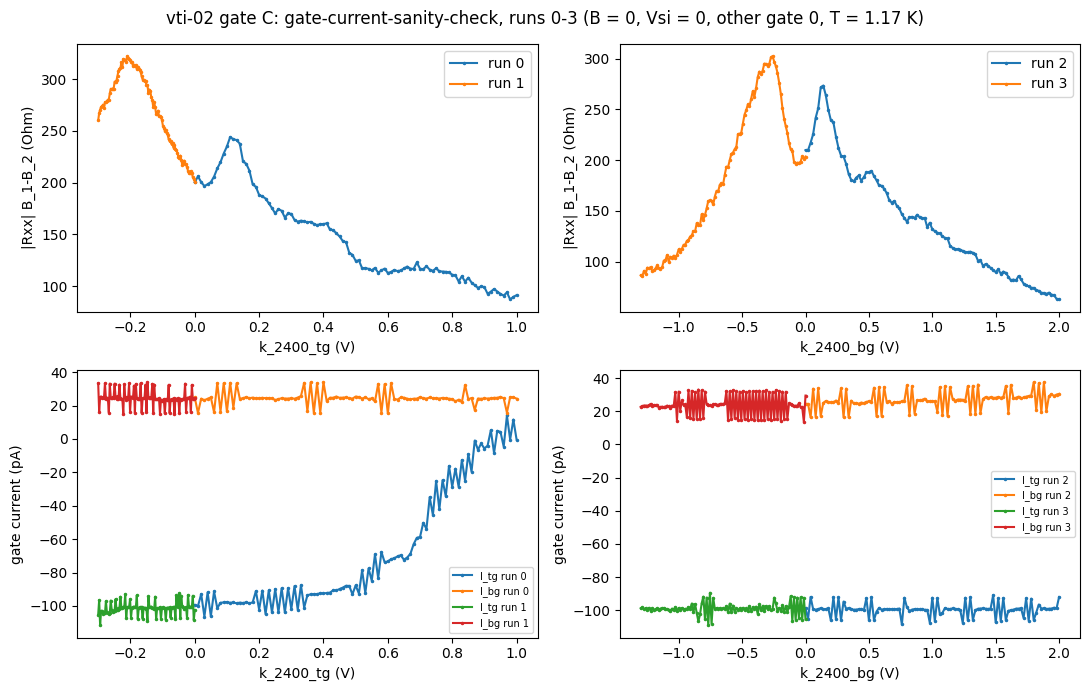

In [6]:
# Gate C — runs 0-3 (gate-current-sanity-check). Raw first: R = (sr1_X/gain)/I_drain per point, gate currents.
from hera.analysis import resolve_channels
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
peaks = {}
for i in range(4):
    r = run(i)
    ch = {c.cid: c for c in resolve_channels(r.meta)}
    V = r.col(r.swept_axis)
    I = r.col("sr0_X") / ch["sr0"].gain
    R = np.abs((r.col("sr1_X") / ch["sr1"].gain) / I)
    i_tg, i_bg = r.col("k_2400_tg_curr"), r.col("k_2400_bg_curr")
    gate = r.swept_axis.replace("_volt", "")
    k = np.argmax(R); peaks[i] = (gate, V[k], R[k])
    print(f"run {i} {gate} {V[0]:+.2f}->{V[-1]:+.2f} V: R {R.min():.0f}-{R.max():.0f} Ohm (max at {V[k]:+.3f} V), "
          f"I_drain {I.min()*1e9:.2f}-{I.max()*1e9:.2f} nA, I_tg {i_tg.min()*1e12:+.0f}..{i_tg.max()*1e12:+.0f} pA, "
          f"I_bg {i_bg.min()*1e12:+.0f}..{i_bg.max()*1e12:+.0f} pA, T {r.col('T_sample').mean():.3f} K, interrupted={r.interrupted}")
    a = ax[0, 0] if "tg" in gate else ax[0, 1]
    a.plot(V, R, ".-", ms=3, label=f"run {i}"); a.set_xlabel(gate + " (V)"); a.set_ylabel("|Rxx| B_1-B_2 (Ohm)"); a.legend()
    b = ax[1, 0] if "tg" in gate else ax[1, 1]
    b.plot(V, i_tg * 1e12, ".-", ms=3, label=f"I_tg run {i}"); b.plot(V, i_bg * 1e12, ".-", ms=3, label=f"I_bg run {i}")
    b.set_xlabel(gate + " (V)"); b.set_ylabel("gate current (pA)"); b.legend(fontsize=7)
fig.suptitle("vti-02 gate C: gate-current-sanity-check, runs 0-3 (B = 0, Vsi = 0, other gate 0, T = 1.17 K)")
fig.tight_layout(); plt.show()


## Run 5 — 0 T gatemap (`gatemap`) → `cnp-and-dline-calibration`

Raw map (log R, TG fast [−0.3, +1.0] × BG slow [−1.3, +1.2], 20 × 40 mV, sr1 100 µV; run 4 was the same map aborted at 3 min when the ridge railed at 2 kΩ). **Read:** one dominant CNP ridge (A) running from (V_tg, V_bg) ≈ (+1.0, −1.3) to (−0.3, +0.45), plus a fainter **parallel** ridge (B) ≈ 0.19 V lower in V_tg — the second peak of runs 0–3. Ridge A's resistance is 240 Ω near D ≈ 0 and grows to ~2.4 kΩ at raw D ≈ +0.25 V/nm (saturating beyond), i.e. a D-tunable gap; **not a stacking read** (investigation Step 1 addendum: three candidate parents). Fits (ridge position = V_tg vs V_bg rows, so −slope = c_bg/c_tg): ridge A in the operating window |V_bg| < 0.5: slope −0.773 (rms 19 mV); high-D rows: −0.763 (rms 6 mV); ridge B: −0.69 (8 rows, rms 13 mV). **Calibration:** ratio c_bg/c_tg = 0.773 (data-calibrated; prior 0.864, −11 % — plausible hBN-thickness error, not a transposition); c_tg anchored at the 9.5 nm prior (absolute scale = geometry prior, pending a lever-arm check); n_offset = −0.089×10¹²; **D_offset from the R_CNP(D) symmetry** (vertex of the ridge-A resistance minimum, ≈ +0.012 raw) — the one feature that physically locates D = 0. Region B is electron-doped by 0.43×10¹² relative to A: a series-mosaic confound (same template expected, 13 % higher n at the fan density — extra tones at ×1.13). Realized D = 0 window inside the validators: **n = −1.27 … +3.27×10¹²** (TG-limited on both ends). Channel arithmetic: R = (sr1_X/1)/(sr0_X/−1e6).


run 5: 63 rows x 66; R 50-3068 Ohm; prior c_bg/c_tg = 0.864
--- ridge A (main) ---
A all rows: 29/30 rows, Vbg [-2.00,+2.00]: Vtg = -0.7308 Vbg +0.0474; c_bg/c_tg = 0.731; rms 15.5 mV
A high-D rows: 16/16 rows, Vbg [-2.00,-0.60]: Vtg = -0.7630 Vbg +0.0129; c_bg/c_tg = 0.763; rms 5.6 mV
A operating window |Vbg|<0.5: 12/12 rows, Vbg [-0.50,+0.50]: Vtg = -0.7728 Vbg +0.0512; c_bg/c_tg = 0.773; rms 19.2 mV
--- ridge B (parallel, lower Vtg) ---
B all rows: 8/8 rows, Vbg [-2.00,+2.00]: Vtg = -0.6909 Vbg -0.1910; c_bg/c_tg = 0.691; rms 13.0 mV
B operating window: 8/8 rows, Vbg [-0.50,+0.50]: Vtg = -0.6909 Vbg -0.1910; c_bg/c_tg = 0.691; rms 13.0 mV

CALIBRATION (ridge A, operating window): ratio 0.773 (prior 0.864, -11%), c_tg 2.796e-03 F/m2 (prior anchor), c_bg 2.161e-03; n_offset -0.0894e12; closure max|n| on fitted line 0.000e12
ridge B density offset relative to A: n_B = -0.426e12 (std 0.026), i.e. region B is electron-doped vs A by 0.43e12
D = 0 line (region A) realized n-window inside v

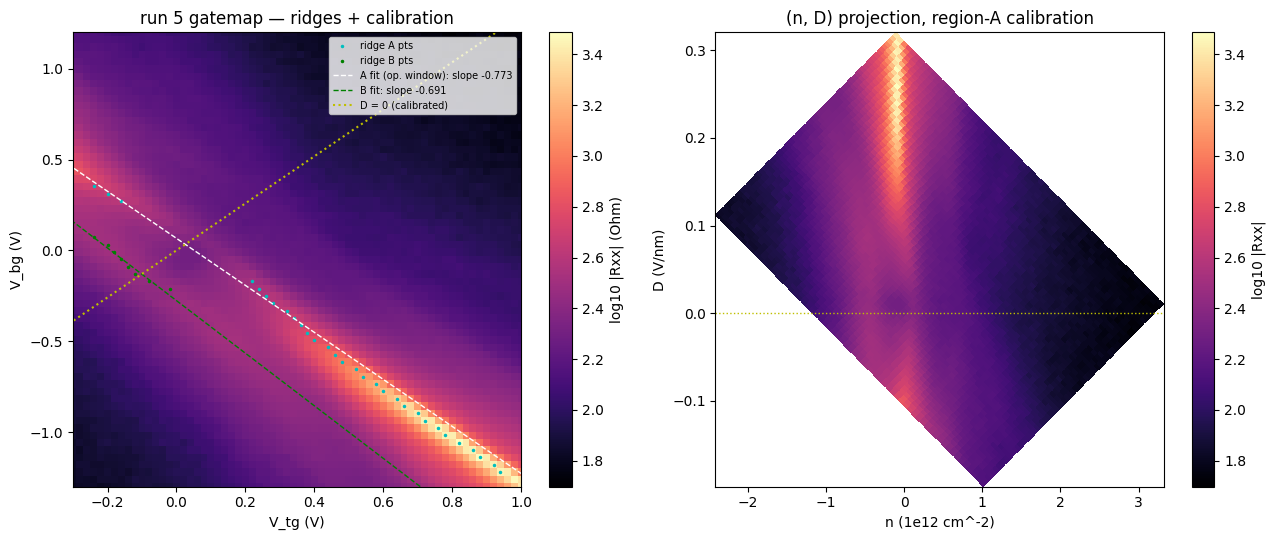

R_CNP(D) minimum: 297 Ohm at raw D = +0.048; parabola vertex raw D = +0.0130 V/nm -> D_offset = -0.0130


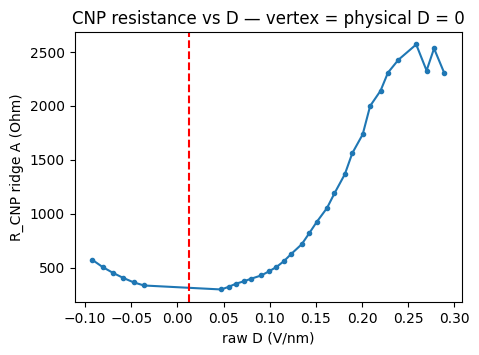

In [7]:
"""cnp-and-dline-calibration on gatemap run 5: per-row ridge extraction (two ridges), ratio fit on the
operating window near D = 0, offsets, closure check, realized D = 0 n-window; writes cal params to JSON."""
import json
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
from sharpelab_nb.gates import stack_capacitance, calc_nD, calc_gate_voltages

rid = 5
g = fan_grids(str(Path(file_path) / str(rid))); rg = resistance_grids(g)
R = np.abs(rg.R["sr1"]); Vbg = g.slow
fs = g.meta["fast_setpoints"]; Vtg = np.asarray(fs[0] if isinstance(fs[0], list) else fs)
c_tg0 = stack_capacitance([(9.5, 3)]); c_bg0 = stack_capacitance([(11, 3)])
print(f"run {rid}: {g.nrows} rows x {g.nfast}; R {R.min():.0f}-{R.max():.0f} Ohm; prior c_bg/c_tg = {c_bg0/c_tg0:.3f}")

# ridge extraction: per row, up to two peaks; track continuity from the high-|D| end where ridge A is unambiguous
pts = []   # (Vbg, Vtg, R, ridge)
for i in range(g.nrows):
    r = gaussian_filter1d(R[i], 1.0)
    pk, _ = find_peaks(r, prominence=0.05 * (r.max() - r.min()) + 5)
    pk = [p for p in pk if 1 < p < g.nfast - 2]
    for p in sorted(pk, key=lambda p: -r[p])[:2]:
        pts.append((Vbg[i], Vtg[p], r[p]))
pts = np.array(pts)
# assign to ridges by distance to the high-D fit of ridge A (rows Vbg < -0.6), then refit each
selA = pts[:, 0] < -0.6
cfA0 = np.polyfit(pts[selA, 0], pts[selA, 1], 1)
dist = pts[:, 1] - np.polyval(cfA0, pts[:, 0])
ridgeA = pts[np.abs(dist) < 0.08]; ridgeB = pts[(dist < -0.08) & (dist > -0.45)]

def fit(p, lo, hi, label):
    m = (p[:, 0] >= lo) & (p[:, 0] <= hi)
    x, y = p[m, 0], p[m, 1]
    if len(x) < 4: print(f"{label}: {len(x)} rows, skip"); return None
    keep = np.ones(len(x), bool)
    for _ in range(3):
        cf = np.polyfit(x[keep], y[keep], 1); res = y - np.polyval(cf, x)
        keep = np.abs(res) < 2.5 * max(np.std(res[keep]), 0.01)
    cf = np.polyfit(x[keep], y[keep], 1); res = (y - np.polyval(cf, x))[keep]
    print(f"{label}: {keep.sum()}/{len(x)} rows, Vbg [{lo:+.2f},{hi:+.2f}]: Vtg = {cf[0]:+.4f} Vbg {cf[1]:+.4f}; "
          f"c_bg/c_tg = {-cf[0]:.3f}; rms {np.std(res)*1e3:.1f} mV")
    return cf

print("--- ridge A (main) ---")
cfA_all = fit(ridgeA, -2, 2, "A all rows")
cfA_hiD = fit(ridgeA, -2, -0.6, "A high-D rows")
cfA_op = fit(ridgeA, -0.5, 0.5, "A operating window |Vbg|<0.5")
print("--- ridge B (parallel, lower Vtg) ---")
cfB_all = fit(ridgeB, -2, 2, "B all rows")
cfB_op = fit(ridgeB, -0.5, 0.5, "B operating window")

# calibration: anchor c_tg at the prior (single hBN dielectric, better constrained), set c_bg from the operating-window ratio
cf = cfA_op if cfA_op is not None else cfA_all
ratio = -cf[0]; c_tg = c_tg0; c_bg = ratio * c_tg
n0, _ = calc_nD(cf[1], 0.0, c_tg, c_bg); n_offset = -n0
nA_ridge = calc_nD(np.polyval(cf, ridgeA[:, 0]), ridgeA[:, 0], c_tg, c_bg, n_offset=n_offset)[0]
print(f"\nCALIBRATION (ridge A, operating window): ratio {ratio:.3f} (prior {c_bg0/c_tg0:.3f}, {100*(ratio/(c_bg0/c_tg0)-1):+.0f}%), "
      f"c_tg {c_tg:.3e} F/m2 (prior anchor), c_bg {c_bg:.3e}; n_offset {n_offset:+.4f}e12; closure max|n| on fitted line {np.abs(nA_ridge).max():.3f}e12")
nB = calc_nD(ridgeB[:, 1], ridgeB[:, 0], c_tg, c_bg, n_offset=n_offset)[0] if len(ridgeB) else np.array([np.nan])
print(f"ridge B density offset relative to A: n_B = {np.nanmedian(nB):+.3f}e12 (std {np.nanstd(nB):.3f}), i.e. region B is {'hole' if np.nanmedian(nB)>0 else 'electron'}-doped vs A by {abs(np.nanmedian(nB)):.2f}e12")
# D = 0 line of region A: V_tg = (c_bg/c_tg) V_bg + V_tg0 where n=0 at ... use calc_gate_voltages
ns = np.linspace(-1.5, 4.5, 601); Vt, Vb = calc_gate_voltages(ns, np.zeros_like(ns), c_tg, c_bg, n_offset=n_offset)
ok = (Vt >= -0.3) & (Vt <= 1.0) & (Vb >= -1.3) & (Vb <= 2.0)
print(f"D = 0 line (region A) realized n-window inside validators: {ns[ok].min():+.2f} .. {ns[ok].max():+.2f} e12; "
      f"CNP at (Vtg, Vbg) = ({calc_gate_voltages(0,0,c_tg,c_bg,n_offset=n_offset)[0]:+.3f}, {calc_gate_voltages(0,0,c_tg,c_bg,n_offset=n_offset)[1]:+.3f})")
# D range along ridge A
DA = calc_nD(ridgeA[:, 1], ridgeA[:, 0], c_tg, c_bg, n_offset=n_offset)[1]
print(f"ridge A spans D = {DA.min():+.3f} .. {DA.max():+.3f} V/nm; peak R vs D: " +
      ", ".join(f"{d:+.2f}:{r:.0f}" for d, r in sorted(zip(np.round(DA, 2), ridgeA[:, 2]))[::6]))
json.dump({"run": rid, "ratio": ratio, "c_tg": c_tg, "c_bg": c_bg, "n_offset": n_offset, "D_offset": float(-D0_raw) if "D0_raw" in globals() else 0.0,
           "slope": cf[0], "intercept": cf[1], "window": "A |Vbg|<0.5", "nB_offset": float(np.nanmedian(nB))},
          open(Path(file_path).parent / "hera_scratch" / "cal_run5.json", "w"), indent=1)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
m = ax[0].pcolormesh(Vtg, Vbg, np.log10(R), shading="nearest", cmap="magma"); fig.colorbar(m, ax=ax[0], label="log10 |Rxx| (Ohm)")
ax[0].plot(ridgeA[:, 1], ridgeA[:, 0], "c.", ms=3, label="ridge A pts"); ax[0].plot(ridgeB[:, 1], ridgeB[:, 0], "g.", ms=3, label="ridge B pts")
xx = np.array([Vbg.min(), Vbg.max()])
ax[0].plot(np.polyval(cf, xx), xx, "w--", lw=1, label=f"A fit (op. window): slope {cf[0]:+.3f}")
if cfB_all is not None: ax[0].plot(np.polyval(cfB_all, xx), xx, "g--", lw=1, label=f"B fit: slope {cfB_all[0]:+.3f}")
ax[0].plot(Vt[ok], Vb[ok], "y:", lw=1.5, label="D = 0 (calibrated)")
ax[0].set_xlim(Vtg.min(), Vtg.max()); ax[0].set_ylim(Vbg.min(), Vbg.max()); ax[0].set_xlabel("V_tg (V)"); ax[0].set_ylabel("V_bg (V)")
ax[0].legend(fontsize=7, loc="upper right"); ax[0].set_title(f"run {rid} gatemap — ridges + calibration")
# (n, D) projection
N, D = calc_nD(Vtg[None, :], Vbg[:, None], c_tg, c_bg, n_offset=n_offset)
m2 = ax[1].pcolormesh(N, D, np.log10(R), shading="nearest", cmap="magma"); fig.colorbar(m2, ax=ax[1], label="log10 |Rxx|")
ax[1].axhline(0, color="y", ls=":", lw=1); ax[1].set_xlabel("n (1e12 cm^-2)"); ax[1].set_ylabel("D (V/nm)"); ax[1].set_title("(n, D) projection, region-A calibration")
fig.tight_layout(); plt.show()

# D_offset from the CNP-resistance symmetry in ±D (ridge A only, n within 0.1e12 of the fit line)
rows = []
for i in range(g.nrows):
    vc = cf[0] * Vbg[i] + cf[1]
    if vc < Vtg.min() + 0.03 or vc > Vtg.max() - 0.03: continue
    msk = np.abs(Vtg - vc) < 0.12
    r = gaussian_filter1d(R[i], 1.0); j = np.argmax(np.where(msk, r, -1))
    n_j, D_j = calc_nD(Vtg[j], Vbg[i], c_tg, c_bg, n_offset=n_offset)
    if abs(n_j) < 0.1: rows.append((D_j, r[j]))
rows = np.array(sorted(rows)); k = np.argmin(rows[:, 1]); sel = np.abs(rows[:, 0] - rows[k, 0]) < 0.12
cq = np.polyfit(rows[sel, 0], rows[sel, 1], 2); D0_raw = -cq[1] / (2 * cq[0])
print(f"R_CNP(D) minimum: {rows[k,1]:.0f} Ohm at raw D = {rows[k,0]:+.3f}; parabola vertex raw D = {D0_raw:+.4f} V/nm -> D_offset = {-D0_raw:+.4f}")
plt.figure(figsize=(5, 3.5)); plt.plot(rows[:, 0], rows[:, 1], "o-", ms=3); plt.axvline(D0_raw, color="r", ls="--")
plt.xlabel("raw D (V/nm)"); plt.ylabel("R_CNP ridge A (Ohm)"); plt.title("CNP resistance vs D — vertex = physical D = 0"); plt.show()


## Runs 6, 7 — SdH spot checks (`sdh-spot-check`), D = 0, both carrier signs

Step 3 of `investigations/tetralayer-stacking-fs-count`: which tones are present, which
side is cleaner, and the measured onset / sampling / sensitivity to hand to the Step-4 fan.
Raw trace first, then `hera.analysis.sdh_onset` (computed, not eyeballed), then the 1/B FFT
with the mandatory low-B / high-B window split.

- **run 6** — electron, nominal n = +3.20e12 cm⁻², (V_tg, V_bg) = (+0.9836, +1.1661), B 0 → 10 T
- **run 7** — hole, nominal n = −1.20e12 cm⁻², (V_tg, V_bg) = (−0.2770, −0.4650), B 10 → 0.3 T

`R_xx = (sr1_X / 1) / I` with `I = sr0_X / (−1e6)` — the measured drain current, per the
device card's channel table. Frequencies are read against `F_L = (h/4e)·|n|` on the run-5
nominal calibration; the **global density rescale** is pinned on the whole peak set below,
never per tone.


run 6 — electron, nominal n = +3.20e12, F_L = 33.09 T
  B 0.000 -> 10.000 T (921 pts), T_sample 1.165-1.292 K
  I = 9.902 nA; R_xx -32.9 .. 529.6 Ohm; max|R| = 530 = 10.5 % of 5049 Ohm full scale (no rail)
  I_tg: median -1 pA, range [-123, +122] pA (trip 1 nA — never armed)
  I_bg: median +26 pA, range [-67, +117] pA (trip 1 nA — never armed)

sdh_onset: onset_b = 0.30 T (tone 7.1 T) over B [0.30, 10.00] T
  tone    7.1 T: onset  0.30 T  dF  0.31 T  snr_max   40.2  [censored@edge, 2x->14.1T, 3x->22.1T, 4x->29.5T]
  tone   22.1 T: onset  1.36 T  dF  1.57 T  snr_max   37.1  [~3x7.1T]
  tone   14.1 T: onset  1.62 T  dF  1.93 T  snr_max   52.5  [revives-below-gap, ~2x7.1T]
  tone   29.5 T: onset  1.91 T  dF  2.36 T  snr_max   89.0  [~4x7.1T]
  tone    3.0 T: onset  0.30 T  dF  0.31 T  snr_max   59.9  [censored@edge, near-residual]
  tone    9.5 T: onset  0.30 T  dF  0.31 T  snr_max   21.8  [censored@edge]
  tone    4.2 T: onset  0.30 T  dF  0.31 T  snr_max   33.7  [censored@edge]
  tone  

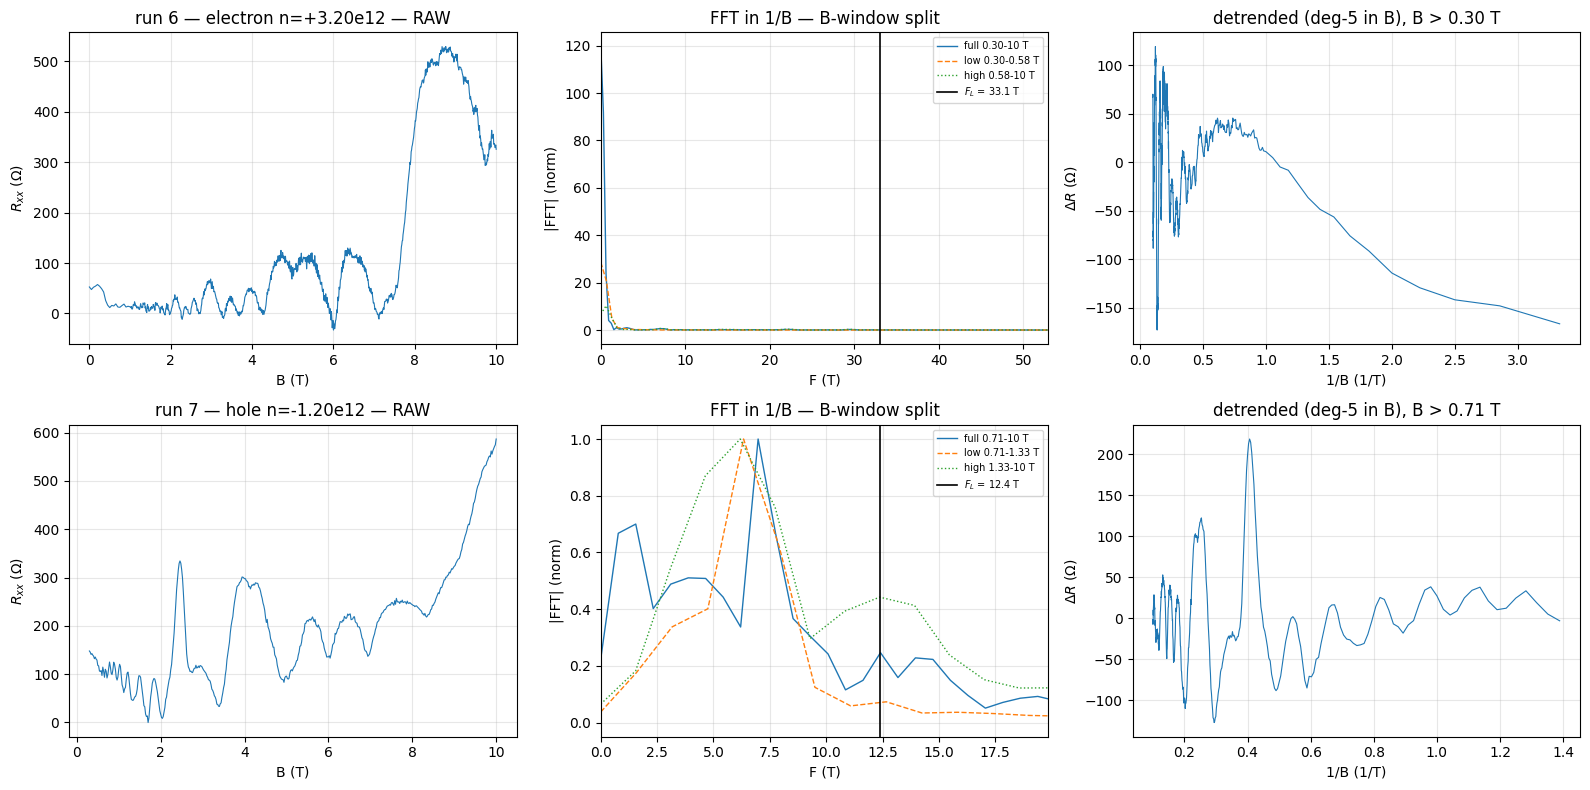

In [4]:
"""Runs 6/7 SdH spot checks: raw -> computed onset -> 1/B FFT with B-window split."""
import warnings

from hera.analysis import sdh_onset, sdh_fft

CAL = dict(c_tg=2.796e-03, c_bg=2.161e-03, n_offset=-0.0894, D_offset=-0.013)
SPOTS = [(6, "electron", +3.20), (7, "hole", -1.20)]


def rxx(r):
    """Four-probe R_xx(B) on sr1, sorted ascending in B, with the measured current."""
    B = r.col("magnet_field")
    I = r.col("sr0_X") / r.meta["measurement_config"]["sr0_gain"]
    R = (r.col("sr1_X") / 1.0) / I           # sr1 gain = 1 (device card)
    o = np.argsort(B)
    return B[o], R[o], I[o]


fig, axes = plt.subplots(2, 3, figsize=(16, 8))
spot_read = {}

for k, (rid, side, n12) in enumerate(SPOTS):
    r = run(rid)
    B, R, I = rxx(r)
    F_L = abs(n12) * 1e16 * cst.h / (4 * cst.e)
    r_fs = 50e-6 / abs(np.median(I))    # both spot checks ran sr1 at 50 uV -> ~5 kOhm FS

    print("=" * 72)
    print(f"run {rid} — {side}, nominal n = {n12:+.2f}e12, F_L = {F_L:.2f} T")
    print(f"  B {B.min():.3f} -> {B.max():.3f} T ({len(B)} pts), "
          f"T_sample {r.col('T_sample').min():.3f}-{r.col('T_sample').max():.3f} K")
    print(f"  I = {np.median(I) * 1e9:.3f} nA; R_xx {R.min():.1f} .. {R.max():.1f} Ohm; "
          f"max|R| = {np.abs(R).max():.0f} = {100 * np.abs(R).max() / r_fs:.1f} % of "
          f"{r_fs:.0f} Ohm full scale (no rail)")
    for g, lbl in (("k_2400_tg_curr", "I_tg"), ("k_2400_bg_curr", "I_bg")):
        c = r.col(g)
        print(f"  {lbl}: median {np.median(c) * 1e12:+.0f} pA, range "
              f"[{c.min() * 1e12:+.0f}, {c.max() * 1e12:+.0f}] pA (trip 1 nA — never armed)")

    # --- 0. RAW first
    ax = axes[k, 0]
    ax.plot(B, R, lw=0.8)
    ax.set(xlabel="B (T)", ylabel=r"$R_{xx}$ ($\Omega$)",
           title=f"run {rid} — {side} n={n12:+.2f}e12 — RAW")
    ax.grid(alpha=0.3)

    # --- 1. onset, computed (landau-fan step-1 B_lo contract)
    with warnings.catch_warnings(record=True) as ws:
        warnings.simplefilter("always")
        on = sdh_onset(R, B, r_full_scale=r_fs)
        print("\n" + on.summary())
        for w in ws:
            print(f"  [warn] {w.message}")
    b_lo, b_hi = on.onset_b, B.max()

    # --- 2. FFT in 1/B, full record + the mandatory low-B / high-B split
    inv_mid = 0.5 * (1 / b_lo + 1 / b_hi)
    b_mid = 1 / inv_mid
    ax = axes[k, 1]
    peaks = {}
    for rng, lab, sty in [((b_lo, b_hi), f"full {b_lo:.2f}-{b_hi:.0f} T", "-"),
                          ((b_lo, b_mid), f"low {b_lo:.2f}-{b_mid:.2f} T", "--"),
                          ((b_mid, b_hi), f"high {b_mid:.2f}-{b_hi:.0f} T", ":")]:
        fr, amp = sdh_fft(R[:, None], B, b_range=rng, nfft=2048, log=False)
        a = amp[0]
        band = (fr > 1.5) & (fr < 2.2 * F_L)
        ax.plot(fr, a / np.nanmax(a[band]), sty, lw=1.0, label=lab)
        loc = band & (a > np.roll(a, 1)) & (a > np.roll(a, -1)) & (a > 0.05 * np.nanmax(a[band]))
        pk, pa = fr[loc], a[loc] / np.nanmax(a[band])
        peaks[lab.split()[0]] = list(zip(np.round(pk, 2), np.round(pa, 2)))
        print(f"  FFT [{lab}]: " + ", ".join(f"{f:.2f}T/{v:.2f}" for f, v in zip(pk, pa)))
    ax.axvline(F_L, color="k", lw=1.2, label=f"$F_L$ = {F_L:.1f} T")
    ax.set(xlabel="F (T)", ylabel="|FFT| (norm)", xlim=(0, 1.6 * F_L),
           title="FFT in 1/B — B-window split")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

    # --- 3. the detrended record the FFT actually sees
    ax = axes[k, 2]
    m = B >= b_lo
    ax.plot(1 / B[m], R[m] - np.polyval(np.polyfit(B[m], R[m], 5), B[m]), lw=0.8)
    ax.set(xlabel="1/B (1/T)", ylabel=r"$\Delta R$ ($\Omega$)",
           title=f"detrended (deg-5 in B), B > {b_lo:.2f} T")
    ax.grid(alpha=0.3)

    spot_read[rid] = dict(side=side, n12=n12, F_L=F_L, onset=b_lo,
                          dF=1 / (1 / b_lo - 1 / b_hi), peaks=peaks)
    print(f"  record resolution delta_F = 1/(1/{b_lo:.2f} - 1/{b_hi:.0f}) = "
          f"{spot_read[rid]['dF']:.2f} T")

plt.tight_layout()
plt.show()


**Read — run 6 (electron, nominal n = +3.20e12, F_L = 33.09 T, δF = 0.31 T).** Resolved set
(rel. amplitude): **7.11** (0.60), **14.22** (0.20), **15.46** (0.17), **22.26** (0.26),
**29.37** (0.24) T, over a low-frequency detrend residual at 1.85/3.09 T (`sdh_onset` flags
its 3.0 T tone `near-residual` — not a pocket). The set closes on **two fundamentals**:
with f_l = 7.11 and f_h = 22.26, 2f_l = 14.22 ✓, f_h − f_l = 15.15 (seen 15.46) ✓,
f_h + f_l = 29.37 (seen 29.37) ✓. The pair **sums to 29.37 T = 0.888 · F_L**, i.e. a single
global density rescale of **0.888** — inside the 0.8–1.2 plausible band — with partition
f_l/Σf = **0.242** and ratio f_h/f_l = **3.13**. Oscillations are **censored at the record's
low edge**: the 7.1 T tone is still above threshold at 0.30 T, so the onset was never
captured and 0.30 T is a *lower bound*, not a measurement.

**What this single density does and does not decide.** The ratio 3.13 is within 4 % of
exactly 3, so a harmonic ladder on 7.11 (3× = 21.33, 4× = 28.44) is not excluded by the
ratio — and the investigation forbids screening the heavy tone on ratio alone. But the
**Luttinger sum** already discriminates: a lone pocket at 7.11 T implies n = 0.69e12 against
the gates' 3.20e12, a 4.6× lever-arm error, and an ABCA singleton would need a private
scale of 0.215 to sit at 7.11 T — red flags, not fits. Both 4L/3L overlays (next cell, the
mandatory dual overlay) put the measured pair on the **ABAB** family: at true
n = 2.84e12 ABAB predicts (6.17, 23.21) T, ratio 3.76, partner fraction 0.210 against the
measured (7.11, 22.26), 3.13, 0.242 — while the trilayer ML+BL template predicts
(1.45, 27.94) T, ratio 19.3, partner fraction 0.049, nowhere near. So: **ABAB-leaning, not
yet a verdict** — it rests on one density, and the 29.37 T tone sitting at the rescaled F_L
is exactly the breakdown/intermodulation confound the investigation calls *expected*, whose
origin discrimination is mandatory before any call.

**Read — run 7 (hole, nominal n = −1.20e12, F_L = 12.41 T, δF = 0.77 T).** Onset **measured**
(not censored) at 0.71 T. Dominant 6.98 T with 13.96 = 2 × 6.98, plus a tone at 12.41 T
sitting on F_L. No pair separates. This is the investigation's flagged **near-CNP hole
exception regime** (|n| ≲ 2–3e12: the ABAB pair is close and balanced, beat-like on short
1/B records) — and the D = 0 line inside the validators reaches only n = −1.27e12, so the
hole side **cannot leave that regime this cooldown**. Non-decisive by construction, as the
proposing cell priced it.

**Side call — electron.** (1) onset 0.30 T *censored* vs 0.71 T *measured*: the electron
side oscillates below the field where the hole side has died; (2) it reaches nominal
+3.27e12 (true ≈ 2.9e12), clear of the low-|n| exception regime the hole side is trapped
in; (3) it resolves a partner-plus-heavy pair with coherent intermodulation bookkeeping,
which the hole record does not. **Step 4 fans the electron side.** Handed forward: B_lo
lower bound 0.30 T (censored), uniform-1/B sampling, dwell at the settling floor
(τ = 0.3 s, 24 dB/oct), and max|R| ≤ 12 % of a 5 kΩ full scale at both spots — neither of
which visited the fan's worst corner (low n × high B).


### Step-4 fan design — dual overlay + the `landau-fan` step-1 numbers

The binding overlay (investigation Verify): **both** families computed, ABAB *and* trilayer
ML+BL, because a lopsided pair summing to F_L passes the loose "pair partitioning F_L"
template while actually tracking the trilayer curves. The discriminator is the **trajectory
across density**, never a ratio at one point — which is exactly what the fan buys, since the
ABAB ratio drifts strongly with n while the harmonic-ladder null sits at exactly 3.00
everywhere.


In [5]:
"""Step-4 fan design: dual model overlay (mandatory) + landau-fan step-1 design numbers.

Design authority for tone positions is the forward model's F(n) table, not the bare
0.72/0.28 ratios: hera/models/tetralayer_fs_count (ABAB SWMcC + ABCA 8-band) and
hera/models/trilayer_fs_count (ML+BL, the adjacent-N overlay the investigation's Verify
makes binding for any two-tone pair).
"""
import sys
import importlib

MODELS = "/home/hera/measurement_env/hera/models"
sys.path.insert(0, f"{MODELS}/tetralayer_fs_count")
M4 = importlib.import_module("fs_count_b0")
del sys.modules["fs_count_b0"]
sys.path.insert(0, f"{MODELS}/trilayer_fs_count")
M3 = importlib.import_module("fs_count_b0")

FL = lambda n12: abs(n12) * 1e16 * cst.h / (4 * cst.e)   # noqa: E731  n12 in 1e12 cm^-2
SCALE = (7.11 + 22.26) / FL(3.20)        # global density rescale pinned on run 6's whole pair

# --- fan window and grid (nominal run-5 calibration units)
N_LO, N_HI = 2.00, 3.20
B_LO, B_MAX = 0.60, 10.0
N_B, N_n = 157, 44

print(f"global density scale pinned on run 6 = {SCALE:.3f}\n")
print("=== dual overlay across the fan window (the trajectory is the discriminator) ===")
print("nom n | true n | F_L,nom | ABAB(4L):  f_l    f_h  ratio  frac_l | 3L ML+BL: f_s    f_b  ratio")
for nn in np.linspace(N_LO, N_HI, 7):
    n_si = SCALE * nn * 1e16
    f4 = sorted(x[0] for x in M4.abab_fs(n_si)[1])
    f3 = sorted(x[0] for x in M3.aba_fs(n_si)[1])
    print(f"{nn:5.2f} | {SCALE * nn:6.2f} | {FL(nn):7.2f} | "
          f"{f4[0]:9.2f} {f4[-1]:6.2f} {f4[-1] / f4[0]:6.2f} {f4[0] / sum(f4):7.3f} | "
          f"{f3[0]:8.2f} {f3[-1]:6.2f} {f3[-1] / f3[0]:6.2f}")
print("  harmonic-ladder null hypothesis: ratio == 3.00 at EVERY density, frac_l == 0.250")
print("  ABCA null hypothesis:            one tone at F_L, no partner")

# --- landau-fan step 1: both-axis Nyquist, resolution, period count
span = 1 / B_LO - 1 / B_MAX
dinvB = span / (N_B - 1)
dF = 1 / span
dn = (N_HI - N_LO) / (N_n - 1)
dn_ray = 4 * (cst.e / cst.h) * B_LO * 1e-16
f_h_meas = 22.26

print(f"\n=== grid Nyquist + resolution (B_lo = {B_LO} T, B_max = {B_MAX} T) ===")
print(f"B axis  : 1/B span {span:.4f} 1/T, N_B = {N_B} -> d(1/B) = {dinvB:.5f}, "
      f"F_Nyq = {1 / (2 * dinvB):.1f} T")
print(f"          must clear F_L(n_max) = {FL(N_HI):.1f} T AND 2*f_heavy = {2 * f_h_meas:.1f} T "
      f"(2nd harmonic folding) -> {'OK' if 1 / (2 * dinvB) > 2 * f_h_meas else 'FAIL'}")
print(f"n axis  : ray spacing at B_lo = {dn_ray:.4f}e12; N_n = {N_n} -> dn = {dn:.4f}e12 "
      f"= {dn_ray / dn:.2f} pts/ray ({'OK' if dn_ray / dn >= 2 else 'UNDER the >=2 floor'})")
print(f"resolution: delta_F = {dF:.3f} T")
print("partner-tone period count over the record (>=5 is the binding case, at n_lo):")
for nn in (N_LO, 2.4, 2.8, N_HI):
    f_l = 1.15 * sorted(x[0] for x in M4.abab_fs(SCALE * nn * 1e16)[1])[0]   # model x measured bias
    print(f"  nominal n = {nn:.2f}: expect f_l ~ {f_l:5.2f} T -> {f_l * span:5.2f} periods")

inv_mid = 0.5 * (1 / B_LO + 1 / B_MAX)
print(f"\nF_L-tone origin (mandatory): B-window split at the 1/B midpoint B = {1 / inv_mid:.2f} T, "
      f"each half delta_F = {1 / (1 / B_LO - inv_mid):.2f} T")
print(f"  heavy {f_h_meas} vs F_L-tone 29.37 separated by {29.37 - f_h_meas:.2f} T "
      f"> 2*delta_F_half = {2 / (1 / B_LO - inv_mid):.2f} T -> resolvable in both halves")

B_vec = 1.0 / np.linspace(1 / B_LO, 1 / B_MAX, N_B)
print(f"\nB rows: {B_vec[0]:.3f} -> {B_vec[-1]:.3f} T, dB {np.abs(np.diff(B_vec)).min() * 1e3:.1f} mT "
      f"(low B) .. {np.abs(np.diff(B_vec)).max():.3f} T (high B); "
      f"total field movement {np.abs(np.diff(B_vec)).sum():.2f} T")


global density scale pinned on run 6 = 0.888

=== dual overlay across the fan window (the trajectory is the discriminator) ===
nom n | true n | F_L,nom | ABAB(4L):  f_l    f_h  ratio  frac_l | 3L ML+BL: f_s    f_b  ratio


 2.00 |   1.78 |   20.68 |      2.87  15.48   5.40   0.156 |     0.37  17.98  48.09


 2.20 |   1.95 |   22.75 |      3.41  16.79   4.93   0.169 |     0.51  19.68  38.51


 2.40 |   2.13 |   24.81 |      3.95  18.08   4.58   0.179 |     0.67  21.36  32.03


 2.60 |   2.31 |   26.88 |      4.50  19.36   4.30   0.189 |     0.84  23.03  27.43


...

 3.20 |   2.84 |   33.09 |      6.17  23.21   3.76   0.210 |     1.45  27.94  19.30
  harmonic-ladder null hypothesis: ratio == 3.00 at EVERY density, frac_l == 0.250
  ABCA null hypothesis:            one tone at F_L, no partner

=== grid Nyquist + resolution (B_lo = 0.6 T, B_max = 10.0 T) ===
B axis  : 1/B span 1.5667 1/T, N_B = 157 -> d(1/B) = 0.01004, F_Nyq = 49.8 T
          must clear F_L(n_max) = 33.1 T AND 2*f_heavy = 44.5 T (2nd harmonic folding) -> OK
n axis  : ray spacing at B_lo = 0.0580e12; N_n = 44 -> dn = 0.0279e12 = 2.08 pts/ray (OK)
resolution: delta_F = 0.638 T
partner-tone period count over the record (>=5 is the binding case, at n_lo):


  nominal n = 2.00: expect f_l ~  3.30 T ->  5.17 periods


  nominal n = 2.40: expect f_l ~  4.54 T ->  7.12 periods


  nominal n = 2.80: expect f_l ~  5.81 T ->  9.10 periods


  nominal n = 3.20: expect f_l ~  7.09 T -> 11.11 periods

F_L-tone origin (mandatory): B-window split at the 1/B midpoint B = 1.13 T, each half delta_F = 1.28 T
  heavy 22.26 vs F_L-tone 29.37 separated by 7.11 T > 2*delta_F_half = 2.55 T -> resolvable in both halves

B rows: 0.600 -> 10.000 T, dB 3.6 mT (low B) .. 0.913 T (high B); total field movement 9.40 T
